# Synthetic Gaussian-Beam Focusing Through Disordered SHU Cavities

**Goal.** Quantify how well a focused beam can be transmitted/focused through a disordered *stealthy hyperuniform* (SHU) slab placed inside a 3D cavity, and how the cavity **air gap** affects that focusing — compared against a purely 2D experiment.

**Key idea — superposition instead of a real beam source.**
Maxwell's equations are linear, so we never actually simulate a Gaussian beam hitting the slab. Instead we run one FDTD simulation *per point-dipole emitter* placed at transverse positions $x = \pm0.5, \pm1.5, \dots, \pm5.5$, and record the transmitted field $E_z(x, \nu)$ on a line behind the slab. Any input beam is then a **weighted coherent sum** of these single-emitter responses:

$$E_z^{\text{beam}}(x,\nu) \;=\; \sum_{j} w_j(\nu)\, E_z^{(j)}(x,\nu)$$

where the complex weights $w_j(\nu)$ encode the amplitude **and phase** that a converging Gaussian beam would have at each emitter location. This lets us synthesize *any* beam (here, a beam focused at a chosen distance) in post-processing from a single reusable set of simulations.

**Pipeline.**
1. **Load** the per-emitter FDTD results for each dataset (2D experiment + 3D cavities with different air gaps).
2. **Build the beam weights** $w_j(\nu)$ from the Gaussian-beam amplitude/phase profile.
3. **Coherently superpose** the emitter fields → synthesized transmitted beam (through slab) and reference (empty cavity).
4. **Quantify focusing** of the exit-line intensity $|E_z|^2$ vs. frequency via the participation ratio (PR) and the beam width $\sigma$.
5. **Visualize & compare** across air gaps.

In [1]:
import scipy.io as sio
from dataclasses import dataclass
from typing import List, Tuple
import os
from dotenv import load_dotenv
load_dotenv()
import tidy3d as td
from tidy3d import web
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from natsort import natsorted
import matplotlib
import h5py
import plotly.graph_objs as go
import plotly
import plotly.express as px
from plotly.subplots import make_subplots
from IPython.display import display, HTML
plotly.offline.init_notebook_mode()
display(HTML(
    '<script type="text/javascript" async src="https://cdnjs.cloudflare.com/ajax/libs/mathjax/2.7.1/MathJax.js?config=TeX-MML-AM_SVG"></script>'
))
import pandas as pd
import sys
import os
import re


from AutomationModule import * 

import AutomationModule as AM

In [2]:
tidy3dAPI = os.environ["API_TIDY3D_KEY"]

a=1


## Step 1 — Load the per-emitter FDTD field data

Each path below is one **dataset**: the 2D reference experiment, plus a series of **3D cavities** that differ only in their **air gap** (0 mm → 1 mm). Inside each folder there is one result file per emitter, whose transverse position is parsed from the filename (`emmiter_<x>`).

For every emitter we load two simulations via `AM.loadFromFile`:
- `sim_data` — field **with the SHU slab** in the cavity.
- `sim_data0` — the **empty-cavity reference** (same run, no slab).

We convert monitor frequencies to GHz and pull the complex $E_z$ field on **two transverse cut-lines** (both restricted to $|x|\le 50$):
- `field_slab_cavity` — the line just **behind the slab** ($y \le 10$): the transmitted/exit field.
- `field_empty_cavity` — the reference line in the empty cavity ($y \le -5.5555$): the incident "beam at entry".

Everything is stored in the nested dict `data_field_intensities[dataset][emitter_x]`, keyed so we can later sum over emitters for each dataset and frequency.

In [ ]:
data_field_intensities={}

directory = r"H:\phd stuff\tidy3d\data"
for path_direction in [
  r"H:\phd stuff\tidy3d\data\20250625 2D eps 45 4-9GHz Different Dipole Position\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=4.9", #2D Experiment eps 45
  r"H:\phd stuff\tidy3d\data\20250721 0mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 0mm Antenna placed at the z=0
  r"H:\phd stuff\tidy3d\data\20250729 0.15mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 0.15mm Antenna placed at the z=0
  r"H:\phd stuff\tidy3d\data\20250721 0.30mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 0.3mm Antenna placed at the z=0
  r"H:\phd stuff\tidy3d\data\20250721 0.50mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 0.5mm Antenna placed at the z=0
  r"H:\phd stuff\tidy3d\data\20250721 0.55mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 0.55mm Antenna placed at the z=0
  r"H:\phd stuff\tidy3d\data\20250721 0.65mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 0.65mm Antenna placed at the z=0
  r"H:\phd stuff\tidy3d\data\20250721 1mm Gap Cavity 3D\chi_0.37_N_10000_posics\chi_0.37_N_10000_posics_L=11",#Separation 1mm Antenna placed at the z=0
                       ]:
  sim_name = str(Path(*Path(path_direction).parts[-3:-2]))
  print(sim_name)
  if sim_name not in data_field_intensities:
        data_field_intensities[sim_name] = {}

  folder_path = f"{path_direction}"

  for i,filename in enumerate(natsorted(os.listdir(folder_path))):
    if not Path(filename).suffix==".txt":
      continue
    print(filename)
    ##get emitter position 
    emitter_x= float(re.search(r'emmiter_([+-]?\d+(?:\.\d+)?)', filename).group(1))

    if os.path.isfile(os.path.join(folder_path, filename)):
      file=os.path.join(folder_path, filename)
      structure_1 = AM.loadFromFile(key = tidy3dAPI, file_path=file)
      sim_data, sim_data0 = structure_1.sim_data, structure_1.sim_data0
     
      lambdas= ((td.C_0/np.array(np.array(sim_data.simulation.monitors)[0].freqs)))
      freqs = 3e10/(lambdas)  * 1e-9
     
      field =sim_data["freq_monitorFieldOut"].Ez
      field_ref =sim_data0["freq_monitorFieldOut"].Ez

      if emitter_x not in data_field_intensities[sim_name]:
        data_field_intensities[sim_name][emitter_x] = {}
      #Get the line at the back of the slab
      indices_x = np.where(np.abs(field["x"])<=50)[0]
      indices_y = np.array([np.where(np.bool_(field["y"]<=(10)))[0][-1]])
      indices_y_ref = np.array([np.where(np.bool_(field["y"]<=(-5.5555)))[0][-1]]) #Reference at entrance of the slab, y=-5.5555mm, which is the same as the reference monitor in the 2D experiment
      
      data_field_intensities[sim_name][emitter_x]["field_empty_cavity"] =field_ref[indices_x,indices_y_ref,:].values.squeeze()
      data_field_intensities[sim_name][emitter_x]["field_slab_cavity"] =field[indices_x,indices_y,:].values.squeeze()
      data_field_intensities[sim_name][emitter_x]["freqs"]=freqs
      data_field_intensities[sim_name][emitter_x]["line_x"]=field["x"][indices_x]
 


20250625 2D eps 45 4-9GHz Different Dipole Position
chi_0.37_N_10000_posics_emmiter_0.5000 - Sample_0.txt
Configured successfully.


15:11:40 W. Europe Daylight Time WARNING: The grid step in x has a value of     
                                 0.1323 (um), which was detected as being large 
                                 when compared to the central wavelength of     
                                 sources[0] within the medium associated with   
                                 structures[0], given by 0.7512 (um). To avoid  
                                 inaccuracies, it is recommended the grid size  
                                 is reduced.                                    

                                 WARNING: Suppressed 2 WARNING messages.        

chi_0.37_N_10000_posics_emmiter_1.5000 - Sample_0.txt
Configured successfully.


15:11:49 W. Europe Daylight Time WARNING: The grid step in x has a value of     
                                 0.1323 (um), which was detected as being large 
                                 when compared to the central wavelength of     
                                 sources[0] within the medium associated with   
                                 structures[0], given by 0.7512 (um). To avoid  
                                 inaccuracies, it is recommended the grid size  
                                 is reduced.                                    

                                 WARNING: Suppressed 2 WARNING messages.        

... (386 outputs left out)

                                 WARNING: Suppressed 1 WARNING message.         

chi_0.37_N_10000_posics_emmiter_-5.5000 - Sample_0.txt
Configured successfully.


19:30:07 W. Europe Daylight Time WARNING: Structure at 'structures[0]' has      
                                 bounds that extend exactly to simulation edges.
                                 This can cause unexpected behavior. If         
                                 intending to extend the structure to infinity  
                                 along one dimension, use td.inf as a size      
                                 variable instead to make this explicit.        

                                 WARNING: Suppressed 1 WARNING message.         

In [4]:
emitters = np.array([float(x) for x in data_field_intensities[list(data_field_intensities.keys())[0]].keys()])
emitters

array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5, -0.5, -1.5, -2.5, -3.5, -4.5,
       -5.5])

## Step 2 — Gaussian-beam weights $w_j(\nu)$

`calculate_gaussian(emitter, lambda_0)` returns the **complex weight** for the emitter at transverse position `emitter`, i.e. the value a converging Gaussian beam would have at that point in the emitter plane, for wavelength `lambda_0`:

$$w(x,\lambda) \;=\; \underbrace{\exp\!\left[-\left(\tfrac{x}{w(z)}\right)^{2}\right]}_{\text{amplitude envelope}}\;\times\;\underbrace{\exp\!\left[\, i\,k\left(z + \tfrac{x^{2}}{2R(z)}\right)\right]}_{\text{quadratic (curvature) phase}}$$

with the standard Gaussian-beam relations evaluated at the propagation distance `z` (focus distance):

- Rayleigh range $\;z_R = \pi w_0^2/\lambda$
- wavefront radius of curvature $\;R(z) = z\big[1+(z_R/z)^2\big]$
- beam width $\;w(z) = w_0\sqrt{1+(z/z_R)^2}$

Parameters used here: waist $w_0 = 2$, focus distance $z = 22.5$. The **amplitude** tapers the outer emitters (a Gaussian aperture), while the **quadratic phase** is what makes the emitters constructively interfere at the focus — this is the numerical equivalent of curving the incoming wavefront to focus the beam.

The cell below just lists the available emitter positions used as summation points.

In [5]:
def calculate_gaussian(emitter,lambda_0):
    z=22.5
    w_0=2
    z_r = np.pi*w_0**2/lambda_0
    R = z*(1+(z_r/z)**2)
    w_z = w_0*np.sqrt(1+(z/z_r)**2)
    amplitudes =  np.exp(-(emitter/a)**2 / w_z**2)  # Gaussian distribution
    k_number = 2 * np.pi / lambda_0
    phases =k_number * (z + (emitter/a)**2 / (2 * R))  # Quadratic phase shift

    return amplitudes * np.exp(1j * phases)


In [6]:
# %matplotlib widget
# from ipywidgets import interact, IntSlider, fixed

# def plot_beam(data,slice_idx):
#     colors = [
#                   (1, 1, 1),  # White
#                   (0, 0, 1),  # Blue
#                   (1, 1, 0),  # Yellow
#                   (0, 1, 0),  # Green
#                   (1, 0, 0), #Red
#                   (0, 0, 0), # Black
#                   ]  
        
#         # Create a custom colormap
#     n_bins = 500  # Number of bins for smooth transition
#     cmap = mcolors.LinearSegmentedColormap.from_list("custom_colormap", colors, N=n_bins)
#     fig, ax = plt.subplots(1,len(data),figsize=(10,10))

    
#     for i, axi in enumerate(ax.flat):
#         value = (np.abs(data[i])**2)[:,:,slice_idx]/np.max((np.abs(data[i])**2)[:,:,slice_idx])
#         im=axi.imshow(value, 
#                          extent =[np.min(field_ref["x"]),np.max(field_ref["x"]),np.min(field_ref["y"]),np.max(field_ref["y"])], 
#                             origin ='lower', cmap=cmap,aspect='auto',norm=LogNorm(vmin=np.min(value), vmax=np.max(value)))
    
#         cbar = fig.colorbar(im, ax=axi, orientation='horizontal', pad=0.03, location="top", shrink=0.3)
#         cbar.ax.text(1.05, 0.5, rf"$\log{{|E|^2}}$", va='center', ha='left', transform=cbar.ax.transAxes)

    
#         axi.set_xlabel(rf"x")
#         axi.set_ylabel(rf"y")

#         axi.tick_params(axis='both', which='major')
#     fig.suptitle(rf"{freqs[slice_idx]:.4f} GHz", fontsize=12,  x=0.5)
#     plt.tight_layout()
#     plt.show()


In [7]:
from matplotlib.colors import LogNorm

def plot_line_intensity(data,freqs_list,lines_x,titles:any=None, log:bool=True):
    colors = [
                  (1, 1, 1),  # White
                  (0, 0, 1),  # Blue
                  (1, 1, 0),  # Yellow
                  (0, 1, 0),  # Green
                  (1, 0, 0), #Red
                  (0, 0, 0), # Black
                  ]  
        
        # Create a custom colormap
    n_bins = 500  # Number of bins for smooth transition
    cmap = mcolors.LinearSegmentedColormap.from_list("custom_colormap", colors, N=n_bins)
    fig, ax = plt.subplots(int(len(data)/2),2,figsize=(15,5*int(len(data)/2)))

    for i, axi in enumerate(ax.flat):
            intensity = np.abs(data[i])**2
            # intensity[intensity/np.max(intensity)<=1e-4]=0
            value = (intensity)/np.max(intensity)
            # value[np.isnan(value)]=0
            if log:
                im=axi.imshow(value, 
                        extent =[np.min(freqs_list[i]),np.max(freqs_list[i]),np.min(lines_x[i]),np.max(lines_x[i])], 
                           origin ='lower', cmap=cmap,aspect='auto',norm=LogNorm(vmin=np.min(value), vmax=np.max(value)))
            else: 
                im=axi.imshow(value, 
                        extent =[np.min(freqs_list[i]),np.max(freqs_list[i]),np.min(lines_x[i]),np.max(lines_x[i])], 
                           origin ='lower', cmap=cmap,aspect='auto',vmin=np.min(value), vmax=np.max(value))

            cbar = fig.colorbar(im, ax=axi, orientation='vertical', pad=0.03, location="right", shrink=0.6)
            cbar.ax.text(0.9, 1.1, rf"$\log{{|E|^2}}$", va='center', ha='left', transform=cbar.ax.transAxes)

            axi.set_xlabel(rf"F(GHz)")
            axi.set_ylabel(rf"x")
            axi.tick_params(axis='both', which='major')
            if titles:
                axi.set_title(titles[i])
       
    # fig.suptitle(rf"Line at the back of the slab", fontsize=12,  x=0.5)
    plt.tight_layout()
    plt.show()



## Step 3 — Coherent superposition (synthesize the focused beam)

For each dataset we build the transmitted focused beam by summing every emitter's recorded field, weighted by its Gaussian-beam coefficient, at each frequency:

$$E_z^{\text{beam}}(x,\nu) = \sum_{j} E_z^{(j)}(x,\nu)\, w\big(x_j,\lambda(\nu)\big)$$

- `beam_shaped` — superposition of the **slab** fields → the beam transmitted **through the SHU cavity**.
- `beam_shaped_ref` — the same superposition of the **empty-cavity** fields → the **reference beam at entry** (no disorder), appended at the end as `"Beam At Entry"`.

The sum is complex (amplitude *and* phase preserved), so interference between emitters is what produces — or destroys — the focus. The result is one synthesized exit-line field per dataset, stored in `lines`, with matching `freqs_list` and transverse coordinates `lines_x`.

In [16]:
title_list = ["2D Experiment","Air Gap 0mm","Air Gap 0.15mm","Air Gap 0.30mm","Air Gap 0.50mm","Air Gap 0.55mm","Air Gap 0.65mm","Air Gap 1mm","Beam At Entry"]
lines = []
freqs_list = []
lines_x = []
for n,simulation in enumerate(data_field_intensities.keys()):
    beam_shaped_ref = np.zeros(shape=np.shape(data_field_intensities[simulation][emitters[0]]["field_empty_cavity"]),dtype=np.complex128)
    beam_shaped = np.zeros(shape=np.shape(data_field_intensities[simulation][emitters[0]]["field_empty_cavity"]),dtype=np.complex128)
    for i,item in enumerate(emitters):
        data_ref = data_field_intensities[simulation][item]["field_empty_cavity"]
        data = data_field_intensities[simulation][item]["field_slab_cavity"]
        lambdas= ((td.C_0/np.array(data_field_intensities[simulation][item]["freqs"])))

        beam_shaped_ref += data_ref*np.array([calculate_gaussian(item,lambda_0) for lambda_0 in lambdas/a])
        beam_shaped += data*np.array([calculate_gaussian(item,lambda_0) for lambda_0 in lambdas/a])   
    line_exit = beam_shaped.squeeze()
    line_ref = beam_shaped_ref.squeeze() 
    lines.append(line_exit)
    freqs_list.append(data_field_intensities[simulation][item]["freqs"])
    lines_x.append(data_field_intensities[simulation][item]["line_x"])
    # titles=[f"A - {title_list[n]}","B - Beam at entry"]

lines.append(line_ref)
freqs_list.append(data_field_intensities[simulation][item]["freqs"])
lines_x.append(data_field_intensities[simulation][item]["line_x"])


In [17]:
# interact(
#     plot_beam, 
#     data=fixed(np.stack([beam_shaped,beam_shaped_ref])), 
#     slice_idx=IntSlider(
#         min=0, 
#         max=beam_shaped.shape[-1] - 1, 
#         step=1, 
#         value=0
#     )
# )

## Step 4 — Quantify the focusing

Two scalar metrics summarize how tightly the exit intensity $I(x) = |E_z^{\text{beam}}(x)|^2$ is concentrated, computed **per frequency**:

- **Participation ratio** `calculate_PR` — an effective spot size,
$$\text{PR} = \frac{\left(\int I\,dx\right)^{2}}{\int I^{2}\,dx}.$$
Small PR ⇒ energy concentrated in a narrow spot (good focusing); large PR ⇒ spread out.

- **Beam width** `calculate_sigma` — the standard deviation of the normalized intensity profile,
$$\sigma = \sqrt{\langle x^2\rangle - \langle x\rangle^2}, \qquad \langle f\rangle = \frac{\int f\,I\,dx}{\int I\,dx}.$$

Both are integrated over the transverse line with `scipy.integrate.trapezoid`. Sweeping frequency turns each into a spectrum PR($\nu$) / $\sigma(\nu)$, revealing which frequencies focus best through each cavity.

In [18]:
#Calculate PR 
import scipy.integrate
def calculate_PR(intensity_array,x1:any=field["y"][indices_y]):
    values = intensity_array
    integral_1 = scipy.integrate.trapezoid(values**2, x=x1, axis=0)
    integral_2 = scipy.integrate.trapezoid(values, x=x1,axis=0)**2

    return integral_2/integral_1
def calculate_sigma(intensity_array, x1):
    x1 = np.asarray(x1)
    values = intensity_array

    # Reshape x1 to broadcast over columns (axis=1)
    x1 = x1[:, np.newaxis]  

    norm = scipy.integrate.trapezoid(values, x=x1[:, 0], axis=0)
    mean = scipy.integrate.trapezoid(values * x1, x=x1[:, 0], axis=0) / norm
    mean_sq = scipy.integrate.trapezoid(values * x1**2, x=x1[:, 0], axis=0) / norm
    sigma = np.sqrt(mean_sq - mean**2)
    return sigma

def plot_PR(data,freqs_list,titles:any=None,calculation_method = "PR"):
    colors = [
                  (1, 1, 1),  # White
                  (0, 0, 1),  # Blue
                  (1, 1, 0),  # Yellow
                  (0, 1, 0),  # Green
                  (1, 0, 0), #Red
                  (0, 0, 0), # Black
                  ]  
        
        # Create a custom colormap
    n_bins = 500  # Number of bins for smooth transition
    cmap = mcolors.LinearSegmentedColormap.from_list("custom_colormap", colors, N=n_bins)
    fig, ax = plt.subplots(int(len(data)/2)+1,2,figsize=(15,5*int(len(data)/2)))
    

    for i, axi in enumerate(ax.flat):
        try:
            intensity = np.abs(data[i])**2
            # intensity[intensity/np.max(intensity)<=1e-4]=0
            value = (intensity)/np.max(intensity)
            # value[np.isnan(value)]=0
            if calculation_method == "PR":
                length_value = calculate_PR(value,lines_x[i])
            else: 
                length_value = calculate_sigma(value,lines_x[i])

            axi.plot(freqs_list[i],length_value)
            axi.set_title(titles[i])
            axi.set_ylabel("PR(F) [mm]")
            axi.set_xlabel("F[GHz]")
        except:
            fig.delaxes(axi)
        
    plt.tight_layout()
    plt.show()


## Step 5 — Results & comparison across air gaps

The plots below compare the synthesized focused beam across all datasets:

1. **`plot_line_intensity(..., log=True)`** — exit-line intensity $|E_z^{\text{beam}}|^2$ as a map of transverse position $x$ vs. frequency (log scale), one panel per dataset plus the "Beam At Entry" reference. Bright horizontal features that stay narrow in $x$ indicate a maintained focus.
2. **`plot_line_intensity(..., log=False)`** — same maps on a linear scale, emphasizing the strongest focal features.
3. **`plot_PR(...)`** — the participation ratio spectrum PR($\nu$) for each dataset (switch `calculation_method="sigma"` to plot $\sigma(\nu)$ instead).

**Reading the comparison.** Going down the panels, the only thing that changes among the 3D cases is the **cavity air gap** (0 → 1 mm), so differences in focus quality/PR isolate the effect of the gap on transmission through the SHU slab; the **2D experiment** and the **beam at entry** serve as baselines.

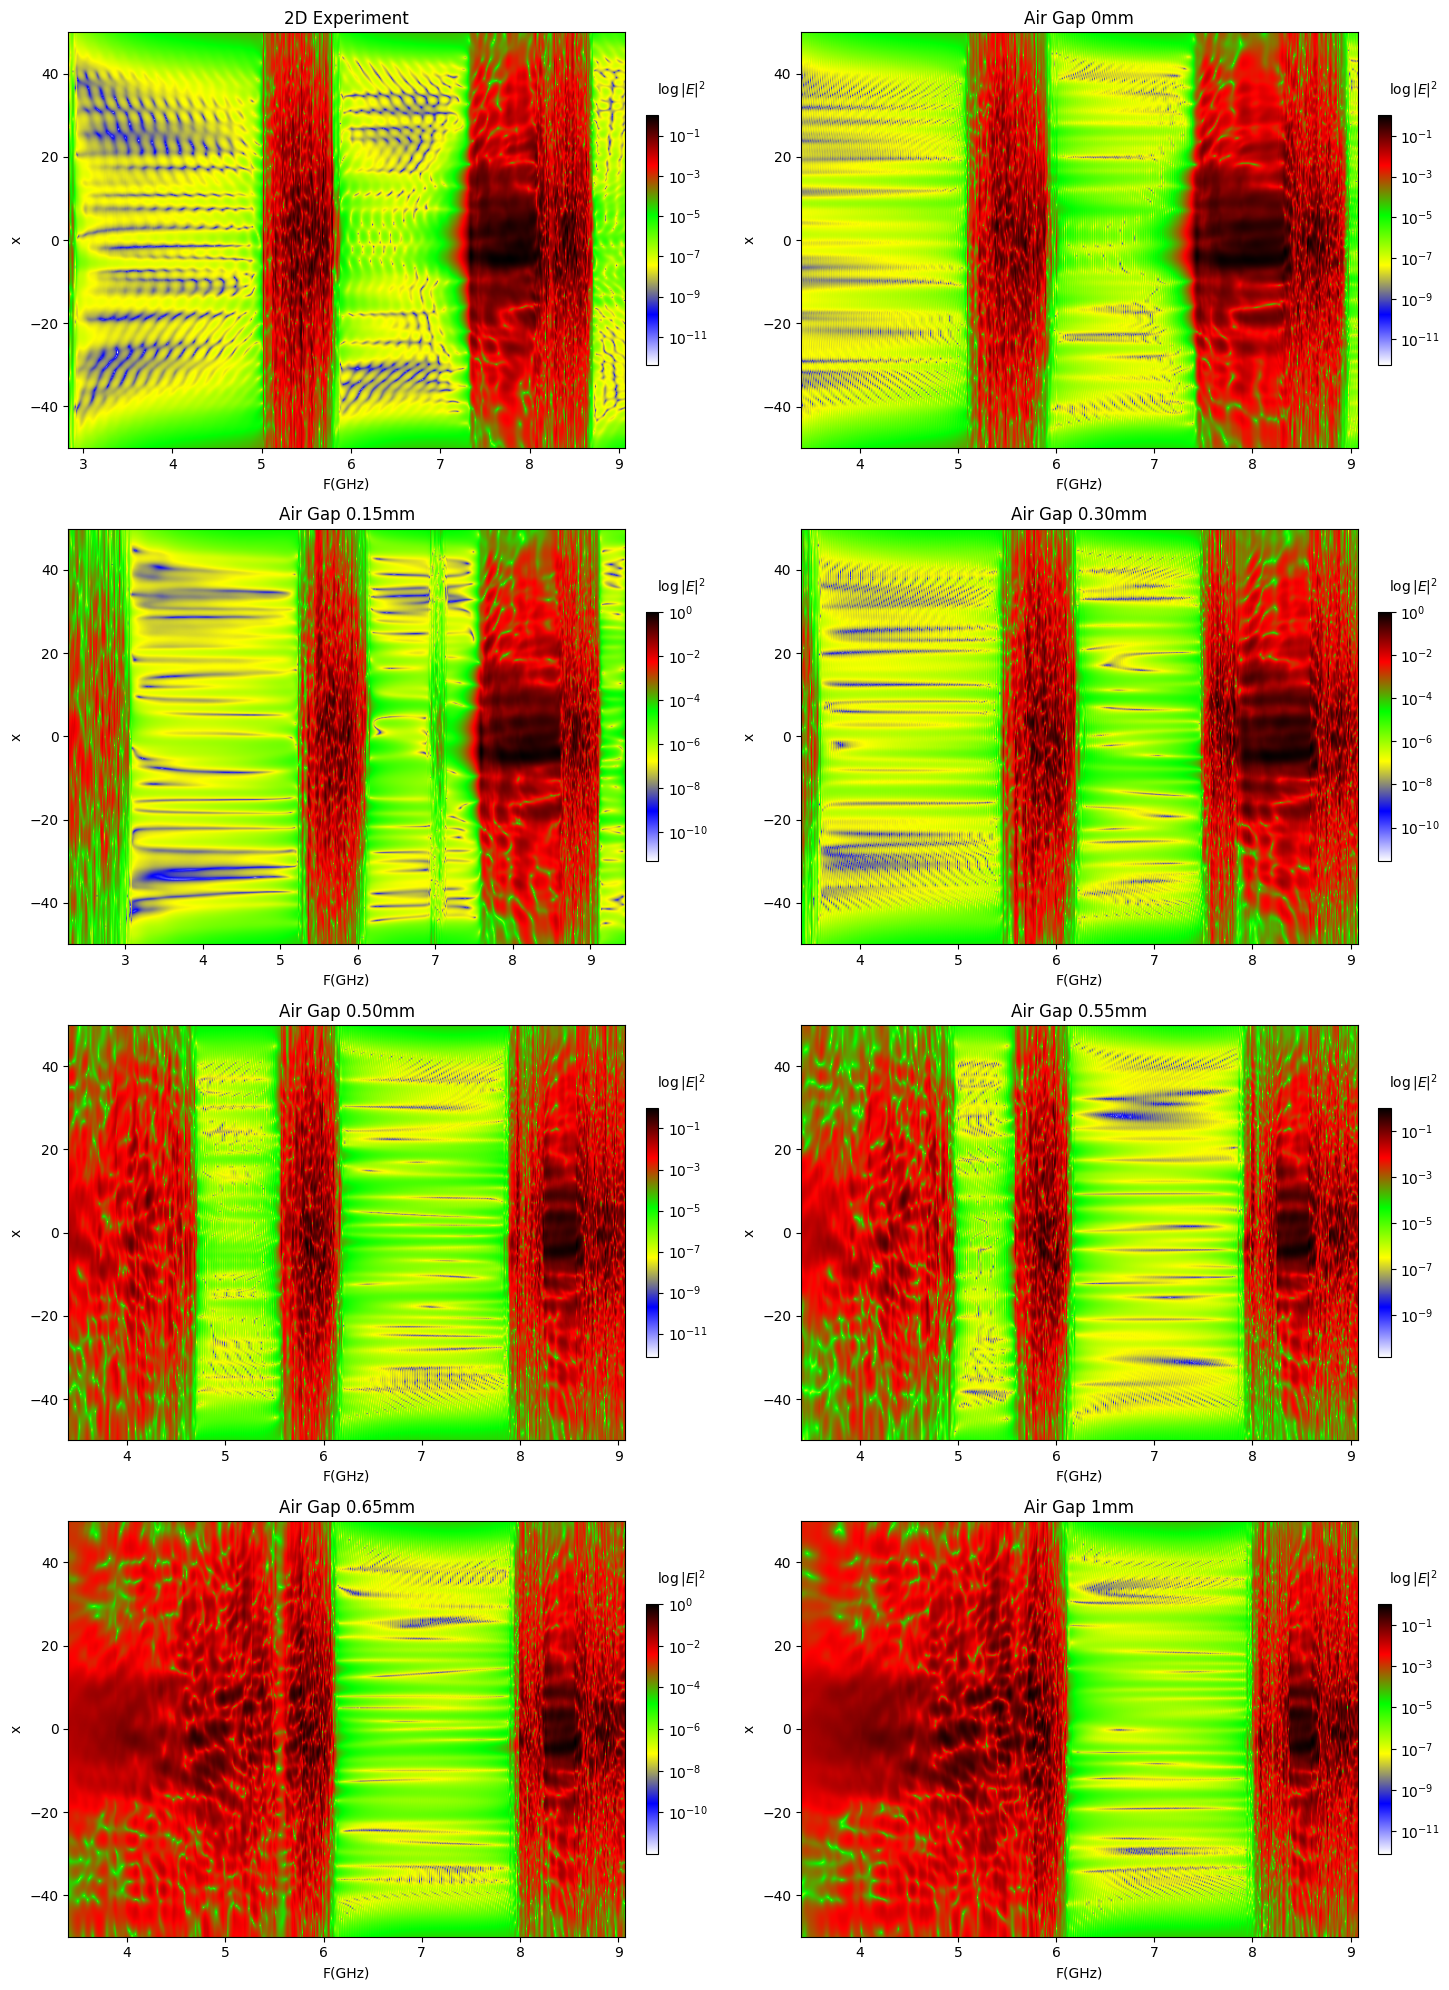

In [19]:
plot_line_intensity(lines,freqs_list,lines_x,title_list)

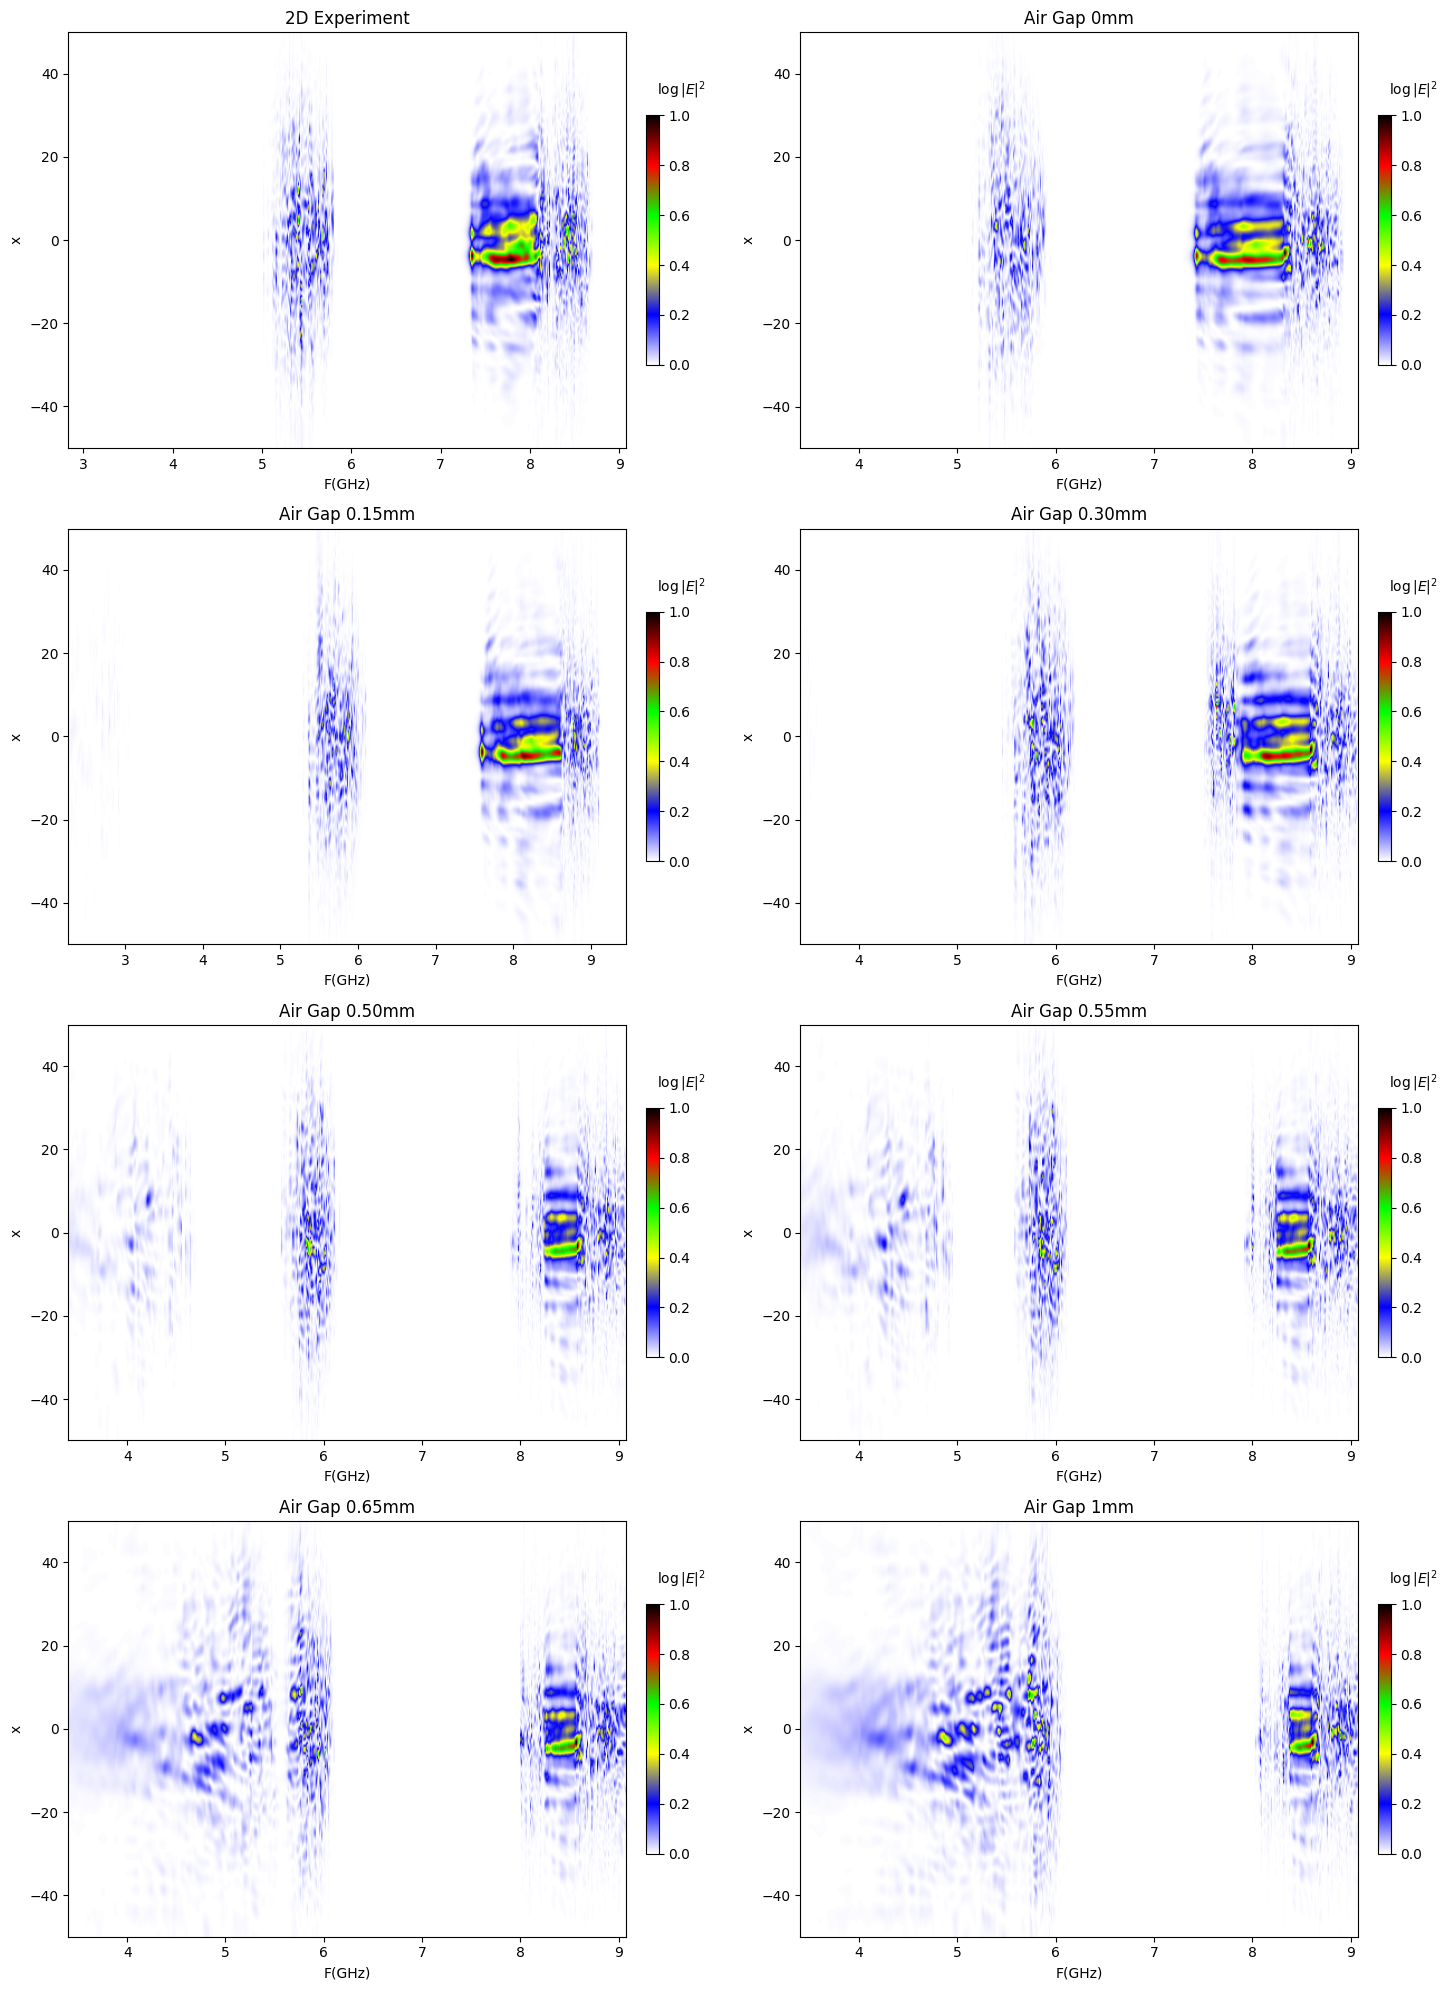

In [20]:
plot_line_intensity(lines,freqs_list,lines_x,title_list,log=False)


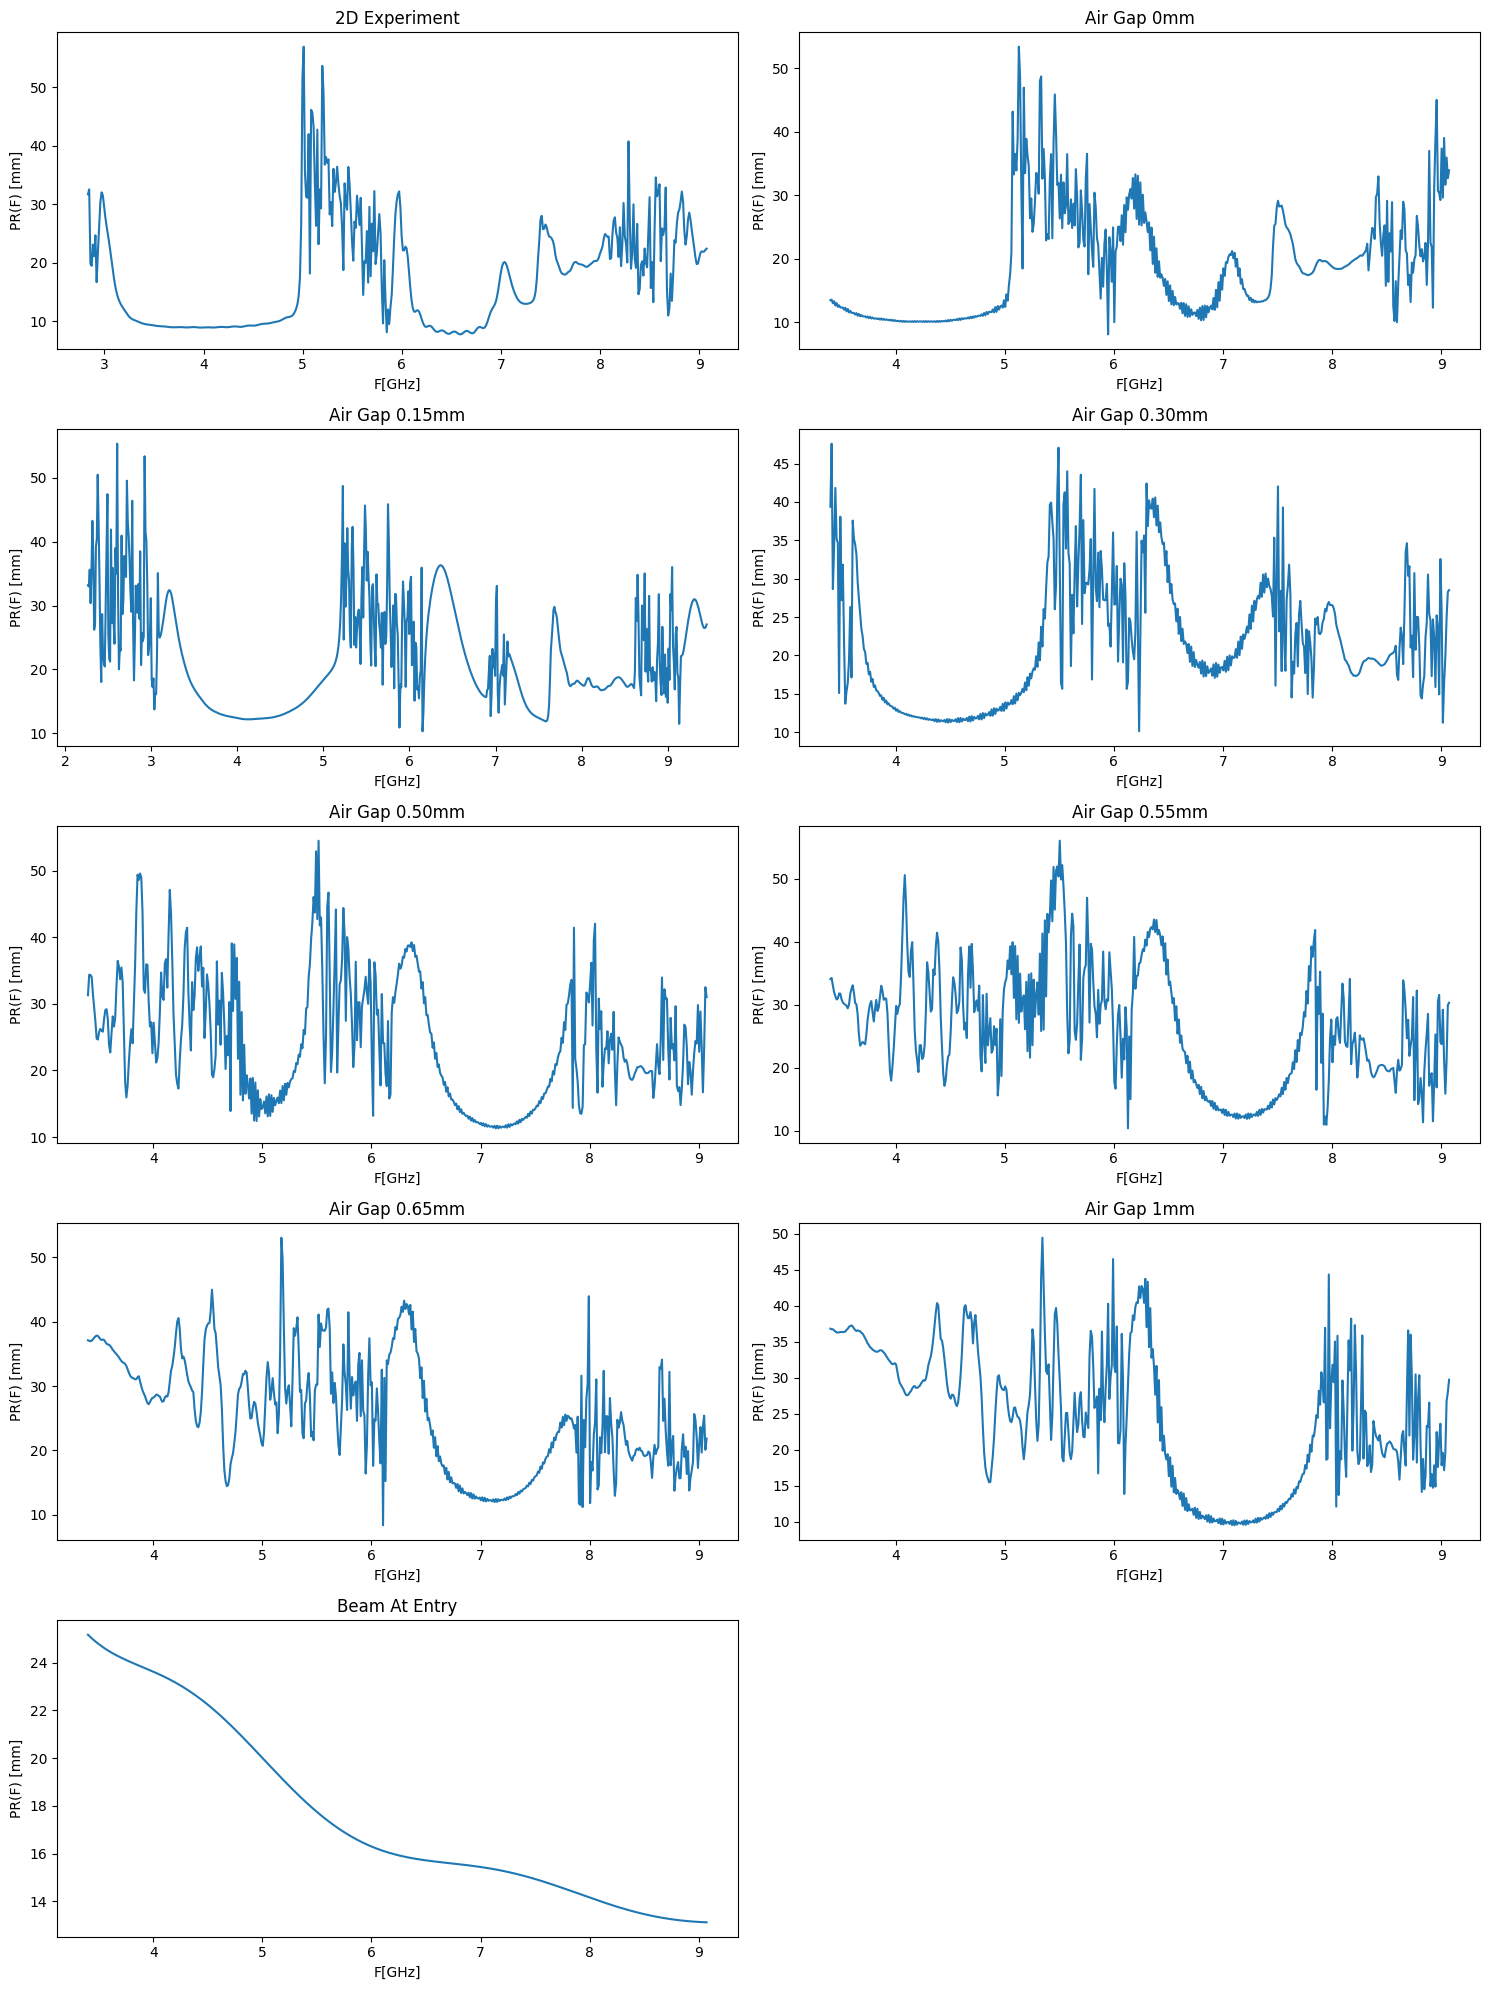

In [21]:
plot_PR(lines,freqs_list,title_list)
